# 110 · What the soap-dispenser rotation angle means

The cardboard unseen-angle wedge (`UNSEEN_ANGLE` / `cardboard_wedge` in `src8/dataset.py`) holds out every `soap-dispenser-rotated` position whose angle is in **30–60°**. That angle is:

- the **long axis** of the object's footprint: the principal axis (largest-eigenvalue eigenvector of the pixel covariance) of `image/03_smask.png`
- measured from the **image +x axis**: the horizontal, pointing right along the columns of `02_cropped_overhead.png`
- in image coordinates, where y (rows) points **down**, so a positive angle turns **clockwise on screen**
- **mod 180°**, because an axis has no head or tail (the soap dispenser's footprint is close to 180° symmetric)

So 0° is horizontal in the photo, 90° is vertical, and the 30–60° wedge is the diagonal running from top-left to bottom-right. The lasers are on the bottom wall of the crop (row fraction 1).

Below: the angle drawn on the overhead photo for 4501 (outside the wedge, so trained or random eval) and 4502 (inside the wedge, eval only).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src8.dataset import EXPERIMENTS, UNSEEN_ANGLE

EXP = '2026_10_11_cardboard_four_objs'
SAMPLES = ['004501-1', '004502-1']

def mask_angle(mk):
    """principal axis of a boolean mask: (centroid (x, y) px, angle in deg in [0, 180) from image +x, clockwise on screen, long/short axis std px)"""
    y, x = np.nonzero(mk)
    cx, cy = x.mean(), y.mean()
    w, v = np.linalg.eigh(np.cov(np.stack([x - cx, y - cy])))   # y DOWN: image coordinates
    ang = np.degrees(np.arctan2(v[1, -1], v[0, -1])) % 180
    return (cx, cy), ang, np.sqrt(w[::-1])

/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


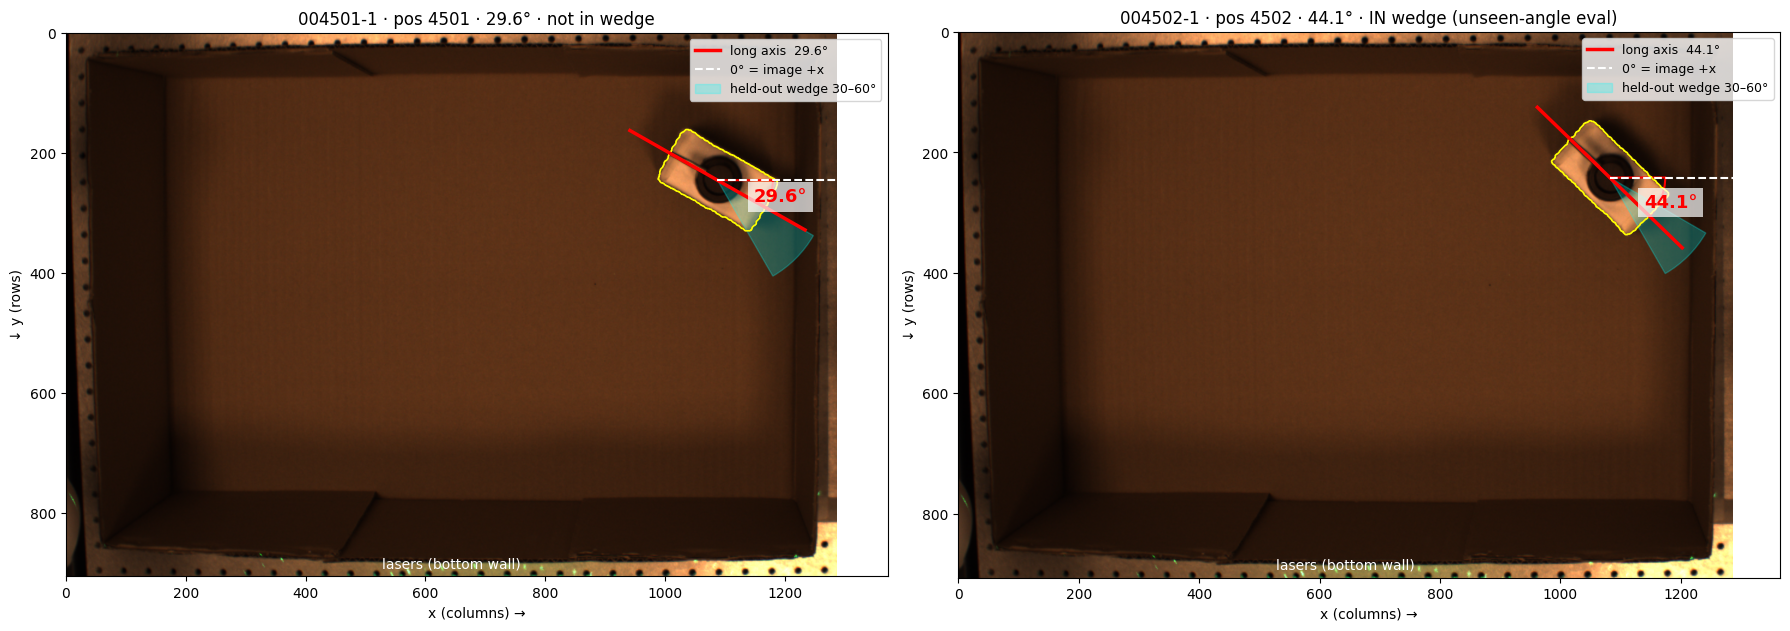

In [2]:
fig, axs = plt.subplots(1, len(SAMPLES), figsize=(9 * len(SAMPLES), 7))
for ax, sid in zip(axs, SAMPLES):
    d = EXPERIMENTS / EXP / 'samples' / sid
    img = np.asarray(Image.open(d / 'image/02_cropped_overhead.png').convert('RGB'))
    mk = np.asarray(Image.open(d / 'image/03_smask.png').convert('L')) > 127
    (cx, cy), ang, (s1, s2) = mask_angle(mk)
    pos = int(sid.split('-')[0])
    ax.imshow(img)
    ax.contour(mk, levels=[0.5], colors='yellow', linewidths=1.2)
    t = np.radians(ang)
    L = 3.2 * s1                                          # half-length of the drawn axis
    ax.plot([cx - L * np.cos(t), cx + L * np.cos(t)], [cy - L * np.sin(t), cy + L * np.sin(t)], color='red', lw=2.5, label=f'long axis  {ang:.1f}°')
    ax.plot([cx, cx + 1.3 * L], [cy, cy], color='white', lw=1.5, ls='--', label='0° = image +x')
    # the held-out 30-60 deg wedge and the measured angle; with y down, Wedge's angles run clockwise on screen, as ours do
    ax.add_patch(Wedge((cx, cy), 1.1 * L, 30, 60, color='cyan', alpha=0.25, label='held-out wedge 30–60°'))
    ax.add_patch(Wedge((cx, cy), 0.55 * L, 0, ang, fill=False, ec='red', lw=1.5))
    ax.text(cx + 0.65 * L * np.cos(t / 2), cy + 0.65 * L * np.sin(t / 2), f'{ang:.1f}°', color='red', fontsize=13, weight='bold',
            ha='center', va='center', bbox=dict(fc='white', ec='none', alpha=0.7))
    ax.annotate('lasers (bottom wall)', (img.shape[1] / 2, img.shape[0] - 10), color='white', ha='center', va='bottom', fontsize=10)
    ax.set_title(f'{sid} · pos {pos} · {ang:.1f}° · ' + ('IN wedge (unseen-angle eval)' if pos in UNSEEN_ANGLE else 'not in wedge'))
    ax.legend(loc='upper right', fontsize=9)
    ax.set_xlabel('x (columns) →'); ax.set_ylabel('↓ y (rows)')
plt.tight_layout(); plt.show()